# v2 — eksperimen A, B, C (Colab)

Ubah `EXPERIMENT` di sel pertama, lalu Run all.

| Kode | Perubahan |
|---|---|
| A | dropout dan label smoothing lebih besar |
| B | tanpa sampler berbobot |
| C | backbone convnext_base |

In [1]:
# === PILIH EKSPERIMEN: "A", "B", atau "C" ===
import copy
EXPERIMENT = "A"

_BASE = {"train": {"epochs": 25, "label_smoothing": 0.2}, "model": {}, "tuned": {"dropout": 0.5}}
EXPERIMENTS = {
    "A": copy.deepcopy(_BASE),
    "B": {**copy.deepcopy(_BASE), "train": {**_BASE["train"], "use_weighted_sampler": False}},
    "C": {**copy.deepcopy(_BASE), "model": {"name": "convnext_base"}},
}
assert EXPERIMENT in EXPERIMENTS, "EXPERIMENT harus A, B, atau C"
EXP = EXPERIMENTS[EXPERIMENT]
print("Eksperimen", EXPERIMENT, "->", EXP)

Eksperimen A -> {'train': {'epochs': 25, 'label_smoothing': 0.2}, 'model': {}, 'tuned': {'dropout': 0.5}}


In [2]:
# === SETUP COLAB (jalankan sekali per sesi) ===
import os, sys, zipfile, subprocess
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')

PAKET = Path('/content/drive/MyDrive/galeria_colab')      # tempat 2 zip diupload
HASIL = Path('/content/drive/MyDrive/galeria_v2_exp') / EXPERIMENT   # hasil per eksperimen (persisten di Drive)
WORK  = Path('/content/ml_exp')                                # folder kerja lokal (cepat)
for z in ('galeria_data_v2.zip', 'galeria_code_v2.zip'):
    assert (PAKET / z).exists(), f'{PAKET / z} belum ada -- upload dulu ke Drive'

if not (WORK / 'src').exists():
    WORK.mkdir(parents=True, exist_ok=True)
    for z in ('galeria_code_v2.zip', 'galeria_data_v2.zip'):
        print('ekstrak', z, '...')
        with zipfile.ZipFile(PAKET / z) as f:
            f.extractall(WORK)

# folder hasil -> symlink ke Drive supaya checkpoint tidak hilang kalau sesi putus
for sub in ('checkpoints', 'outputs', 'export', 'data/cache'):
    real = HASIL / sub.replace('/', '_')
    real.mkdir(parents=True, exist_ok=True)
    (WORK / sub).mkdir(parents=True, exist_ok=True)
    link = WORK / sub / 'v2_exp'
    if link.is_symlink() or link.exists():
        link.unlink()          # eksperimen bisa berganti dalam satu sesi
    link.symlink_to(real, target_is_directory=True)

os.chdir(WORK)
sys.path.insert(0, str(WORK))
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pyyaml', 'faiss-cpu', 'optuna'], check=False)
import torch
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'TIDAK ADA -- aktifkan T4 di Runtime > Change runtime type')
print('gambar:', len(list((WORK / 'data/processed').glob('*.jpg'))), '| kerja di', os.getcwd())

Mounted at /content/drive
ekstrak galeria_code_v2.zip ...
ekstrak galeria_data_v2.zip ...
GPU: NVIDIA A100-SXM4-40GB
gambar: 33520 | kerja di /content/ml_exp


## 1. Setup

In [3]:
%matplotlib inline
import os, sys
from pathlib import Path

# pindah ke folder ml/ supaya `import src` & path config jalan
_p = Path.cwd()
while not ((_p / "src").is_dir() and (_p / "configs").is_dir()):
    if _p == _p.parent:
        raise RuntimeError("folder ml/ (berisi src/ & configs/) tidak ketemu")
    _p = _p.parent
os.chdir(_p)
if str(_p) not in sys.path:
    sys.path.insert(0, str(_p))

import json, math, time, copy
import numpy as np
import pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt
import torchvision

torch.backends.cudnn.benchmark = True   # ukuran input tetap -> cuDNN pilih kernel tercepat

print("working dir :", os.getcwd())
print("python      :", sys.version.split()[0])
print("torch       :", torch.__version__, "| torchvision", torchvision.__version__)
print("CUDA        :", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

working dir : /content/ml_exp
python      : 3.13.15
torch       : 2.11.0+cu130 | torchvision 0.26.0+cu130
CUDA        : True | NVIDIA A100-SXM4-40GB


In [4]:
from src.utils import load_config, set_seed, get_device, resolve_path
from src.dataset import build_label_mapping, create_dataloaders
from src.model import build_model, save_checkpoint, load_checkpoint
from src.train import (build_optimizer, build_scheduler, train_one_epoch,
                       validate, make_scaler)
from src.evaluate import run_inference, compute_metrics

cfg = load_config("configs/config.yaml")
cfg["train"]["num_workers"] = 2            # Colab (Linux): 2 worker aman
cfg["train"]["early_stopping_patience"] = 6   # val plateau cepat -> patience 10 buang ~10 epoch
# cfg["train"]["epochs"] = 8               # <- uncomment untuk uji cepat

# --- OVERRIDE v2 (22 kelas, 33.937 gambar) -- TIDAK sentuh root/continued_training ---
# data.*_csv/cache_dir DIBIARKAN default config.yaml -- itu memang sudah menunjuk
# ke dataset 33.937 gambar/22 kelas yang benar (beda dari v1 yang datanya ketimpa).
cfg["checkpoint"]["dir"] = "checkpoints/v2_exp"
cfg["output"]["dir"] = "outputs/v2_exp"
cfg["output"]["log_file"] = "outputs/v2_exp/train.log"
cfg["output"]["history_plot_path"] = "outputs/v2_exp/training_history.png"
cfg["output"]["history_json_path"] = "outputs/v2_exp/history.json"
cfg["output"]["confusion_matrix_path"] = "outputs/v2_exp/confusion_matrix.png"
cfg["output"]["metrics_report_path"] = "outputs/v2_exp/metrics_report.json"
cfg["embedding"]["output_path"] = "data/cache/v2_exp/catalog_embeddings_regenerated.npz"
cfg["embedding"]["faiss_index_path"] = "data/cache/v2_exp/catalog.faiss"
cfg["export"]["checkpoint"] = "checkpoints/v2_exp/best.pth"
cfg["export"]["torchscript_path"] = "export/v2_exp/model.torchscript"
cfg["export"]["onnx_path"] = "export/v2_exp/model.onnx"

# Hyperparameter hasil tuning Optuna run v1 (trial #13/15, lihat notebooks/README.md) --
# re-tuning utk dataset 6x lebih besar ini bisa >15 jam, tidak realistis utk timeline
# 2 minggu. Diterapkan di bawah lewat blok RUN_TUNING (section 3), bukan di sini.
TUNED_PARAMS = {
    "learning_rate": 0.0002584949196006611,
    "backbone_lr_mult": 0.18427033274320545,
    "weight_decay": 0.0009849813063176139,
    "dropout": 0.2017262123368978,
    "unfreeze_frac": 0.4406353983164585,
}

# --- EKSPERIMEN (lihat sel pilihan di atas) ---
cfg["train"].update(EXP["train"])
cfg["model"].update(EXP["model"])
TUNED_PARAMS.update(EXP["tuned"])     # dropout dll. diterapkan ke cfg di sel tuning (RUN_TUNING=False)
print(f"EKSPERIMEN {EXPERIMENT}: train={EXP['train']} model={EXP['model']} tuned={EXP['tuned']}")

set_seed(cfg["seed"])
device = get_device(cfg["device"])
use_amp = bool(cfg["train"]["mixed_precision"]) and device.type == "cuda"
print("device:", device, "\n")

# variabel BERSAMA (dipakai lintas sel; taruh di sini biar re-run sel individual aman)
MEAN = torch.tensor(cfg["image"]["mean"]).view(3, 1, 1)
STD  = torch.tensor(cfg["image"]["std"]).view(3, 1, 1)

def denorm(t):
    return (t * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

for sec in ["image", "augmentation", "model", "train", "checkpoint", "eval"]:
    print(f"[{sec}]"); print(json.dumps(cfg[sec], indent=2, ensure_ascii=False)); print()

EKSPERIMEN A: train={'epochs': 25, 'label_smoothing': 0.2} model={} tuned={'dropout': 0.5}
device: cuda 

[image]
{
  "size": 224,
  "resize": 256,
  "mean": [
    0.485,
    0.456,
    0.406
  ],
  "std": [
    0.229,
    0.224,
    0.225
  ],
  "pad_to_square": false,
  "pad_mode": "edge",
  "pad_fill": 255
}

[augmentation]
{
  "horizontal_flip": 0.5,
  "rotation_degrees": 10,
  "color_jitter": {
    "brightness": 0.2,
    "contrast": 0.2,
    "saturation": 0.2,
    "hue": 0.05
  },
  "trivial_augment": true
}

[model]
{
  "name": "convnext_small",
  "pretrained": true,
  "train_mode": "finetune_partial",
  "unfreeze_last_n_blocks": 2,
  "unfreeze_frac": 0.4,
  "dropout": 0.4,
  "embedding_dim": 2048
}

[train]
{
  "epochs": 25,
  "batch_size": 24,
  "num_workers": 2,
  "optimizer": "adamw",
  "learning_rate": 0.0003,
  "backbone_lr_mult": 0.1,
  "weight_decay": 0.0005,
  "scheduler": "cosine",
  "step_size": 10,
  "gamma": 0.1,
  "label_smoothing": 0.2,
  "mixed_precision": true,
 

## 2. Data

22 kelas: ['Abstract_Expressionism', 'Art_Nouveau', 'Baroque', 'Color_Field_Painting', 'Cubism', 'Early_Renaissance', 'Expressionism', 'Fauvism', 'High_Renaissance', 'Impressionism', 'Mannerism_Late_Renaissance', 'Minimalism', 'Naive_Art_Primitivism', 'Northern_Renaissance', 'Pointillism', 'Pop_Art', 'Post_Impressionism', 'Realism', 'Rococo', 'Romanticism', 'Symbolism', 'Ukiyo_e']
                            train   val  test
style_name                                   
Impressionism                5269  1129  1129
Realism                      3874   830   830
Post_Impressionism           2148   460   461
Romanticism                  1911   410   409
Expressionism                1481   318   317
Symbolism                    1418   303   304
Art_Nouveau                  1283   275   274
Baroque                      1131   243   242
Northern_Renaissance          903   194   193
Naive_Art_Primitivism         755   162   162
Cubism                        600   128   129
Abstract_Expressio

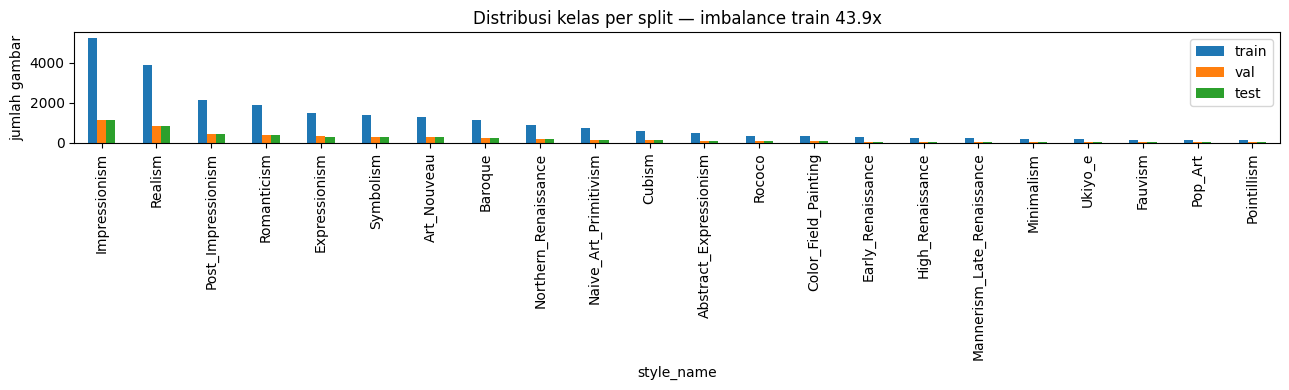

In [5]:
label_to_idx = build_label_mapping(cfg)
idx_to_label = {v: k for k, v in label_to_idx.items()}
num_classes  = len(label_to_idx)
class_names  = [idx_to_label[i] for i in range(num_classes)]   # bersama
print(f"{num_classes} kelas:", class_names)

dist = {}
for name in ("train", "val", "test"):
    d = pd.read_csv(resolve_path(cfg["data"][f"{name}_csv"]))
    dist[name] = d[cfg["data"]["label_column"]].value_counts()
dist = pd.DataFrame(dist).fillna(0).astype(int).sort_values("train", ascending=False)
print(dist)

ax = dist.plot(kind="bar", figsize=(13, 4))
ax.set_title(f"Distribusi kelas per split — imbalance train "
             f"{dist['train'].max()/dist['train'].min():.1f}x")
ax.set_ylabel("jumlah gambar"); plt.tight_layout(); plt.show()

In [6]:
loaders = create_dataloaders(cfg)
print({k: f"{len(v)} batch / {len(v.dataset)} img" for k, v in loaders.items()})

{'train': '977 batch / 23464 img', 'val': '210 batch / 5028 img', 'test': '210 batch / 5028 img'}


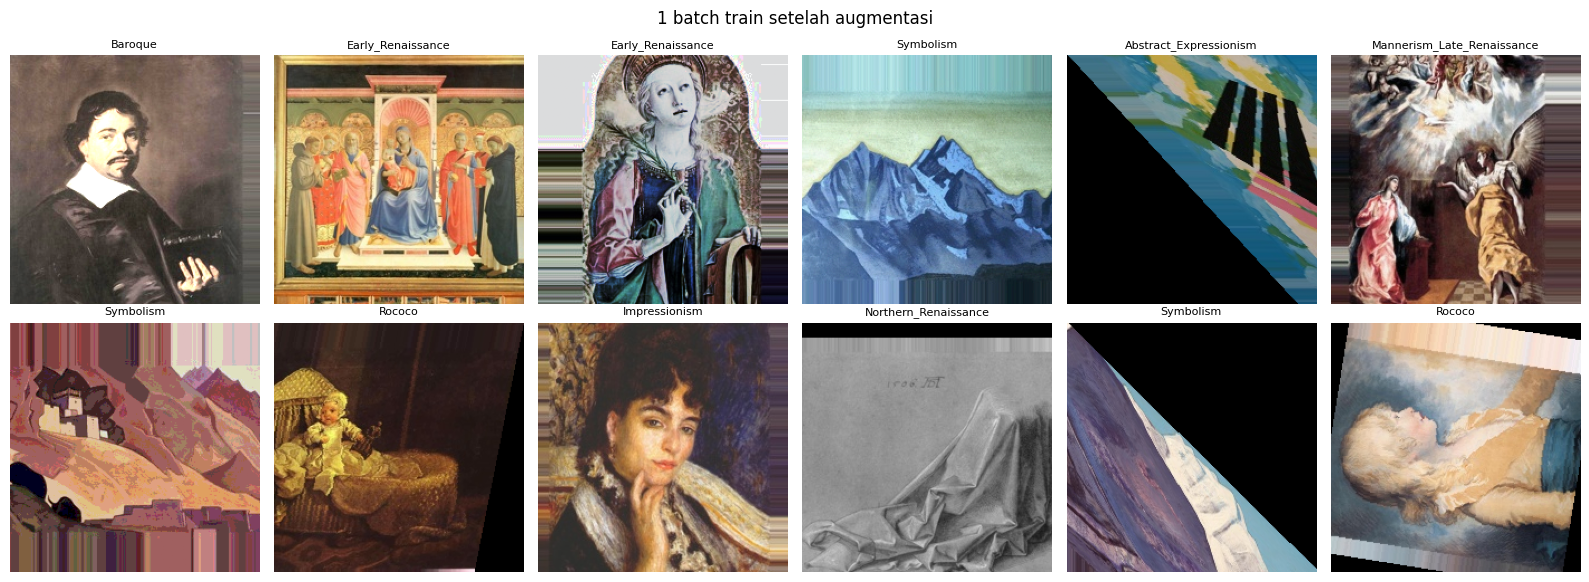

In [7]:
# contoh 1 batch train (SquarePad sudah di-preprocess; ini + augmentasi TrivialAugment)
imgs, labels = next(iter(loaders["train"]))
n = min(12, len(imgs))
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for i, ax in enumerate(axes.flat):
    if i < n:
        ax.imshow(denorm(imgs[i])); ax.set_title(idx_to_label[labels[i].item()], fontsize=8)
    ax.axis("off")
fig.suptitle("1 batch train setelah augmentasi"); plt.tight_layout(); plt.show()

## 3. Hyperparameter Tuning (Optuna) — opsional

In [8]:
RUN_TUNING  = False   # reuse TUNED_PARAMS (hasil tuning v1) -- re-tuning 22 kelas bisa >15 jam
N_TRIALS    = 15
TUNE_EPOCHS = 8        # budget per trial (val kita plateau ~epoch 10 di run penuh)

In [9]:
if RUN_TUNING:
    import optuna
    from optuna.pruners import MedianPruner
    from optuna.samplers import TPESampler

    def objective(trial):
        t_cfg = copy.deepcopy(cfg)
        t_cfg["train"]["learning_rate"]    = trial.suggest_float("learning_rate", 1e-4, 1e-3, log=True)
        t_cfg["train"]["backbone_lr_mult"] = trial.suggest_float("backbone_lr_mult", 0.02, 0.5, log=True)
        t_cfg["train"]["weight_decay"]     = trial.suggest_float("weight_decay", 1e-5, 1e-3, log=True)
        t_cfg["model"]["dropout"]          = trial.suggest_float("dropout", 0.2, 0.6)
        t_cfg["model"]["unfreeze_frac"]    = trial.suggest_float("unfreeze_frac", 0.15, 0.6)
        t_cfg["train"]["epochs"] = TUNE_EPOCHS   # cosine schedule disesuaikan budget trial

        set_seed(cfg["seed"])
        t_model = build_model(t_cfg, num_classes=num_classes).to(device)
        t_crit  = nn.CrossEntropyLoss(label_smoothing=t_cfg["train"]["label_smoothing"])
        t_opt   = build_optimizer(t_cfg, t_model)
        t_sched = build_scheduler(t_cfg, t_opt)
        t_scaler = make_scaler(device.type, use_amp)

        best_f1 = -1.0
        for ep in range(1, TUNE_EPOCHS + 1):
            train_one_epoch(t_model, loaders["train"], t_crit, t_opt, device, t_scaler,
                            t_cfg["train"].get("grad_clip_norm"))
            va = validate(t_model, loaders["val"], t_crit, device)
            if t_sched is not None:
                t_sched.step()
            best_f1 = max(best_f1, va["macro_f1"])
            trial.report(va["macro_f1"], ep)
            if trial.should_prune():
                raise optuna.TrialPruned()
        return best_f1

    study = optuna.create_study(
        study_name="galeria_v2_exp",
        storage=f"sqlite:///{resolve_path('outputs/v2_exp/tune_study.db')}",
        load_if_exists=True,
        direction="maximize",
        sampler=TPESampler(seed=cfg["seed"]),
        pruner=MedianPruner(n_startup_trials=5, n_warmup_steps=3),
    )
    n_done = sum(t.state.is_finished() for t in study.trials)
    print(f"trial sudah selesai sebelumnya: {n_done} (resume otomatis)")
    if n_done < N_TRIALS:
        study.optimize(objective, n_trials=N_TRIALS - n_done, show_progress_bar=True)

    print(f"\nbest trial #{study.best_trial.number} | val macro-F1 = {study.best_value:.4f}")
    print("best params:", json.dumps(study.best_params, indent=2))

    study.trials_dataframe().to_csv(resolve_path("outputs/v2_exp/tune_trials.csv"), index=False)
    resolve_path("outputs/v2_exp/tune_best_params.json").write_text(
        json.dumps(study.best_params, indent=2), encoding="utf-8")

    # terapkan hyperparameter terbaik ke cfg -> dipakai sel Model & Training di bawah
    cfg["train"]["learning_rate"]    = study.best_params["learning_rate"]
    cfg["train"]["backbone_lr_mult"] = study.best_params["backbone_lr_mult"]
    cfg["train"]["weight_decay"]     = study.best_params["weight_decay"]
    cfg["model"]["dropout"]          = study.best_params["dropout"]
    cfg["model"]["unfreeze_frac"]    = study.best_params["unfreeze_frac"]
    print("\ncfg diupdate dengan hyperparameter terbaik -> Training di bawah otomatis memakainya")
else:
    cfg["train"]["learning_rate"]    = TUNED_PARAMS["learning_rate"]
    cfg["train"]["backbone_lr_mult"] = TUNED_PARAMS["backbone_lr_mult"]
    cfg["train"]["weight_decay"]     = TUNED_PARAMS["weight_decay"]
    cfg["model"]["dropout"]          = TUNED_PARAMS["dropout"]
    cfg["model"]["unfreeze_frac"]    = TUNED_PARAMS["unfreeze_frac"]
    print("RUN_TUNING=False -> pakai TUNED_PARAMS (hasil tuning v1, reuse) -> cfg diupdate")

RUN_TUNING=False -> pakai TUNED_PARAMS (hasil tuning v1, reuse) -> cfg diupdate


In [10]:
if RUN_TUNING:
    try:
        import optuna.visualization.matplotlib as ovm
        ovm.plot_optimization_history(study); plt.tight_layout(); plt.show()
        ovm.plot_param_importances(study); plt.tight_layout(); plt.show()
    except Exception as e:
        print("plot Optuna dilewati:", e)

    top = (study.trials_dataframe()
           .query("state == 'COMPLETE'")
           .sort_values("value", ascending=False)
           [["number", "value", "params_learning_rate", "params_backbone_lr_mult",
             "params_weight_decay", "params_dropout", "params_unfreeze_frac"]])
    print(top.head(10).to_string(index=False))

## 4. Model

In [11]:
model = build_model(cfg, num_classes=num_classes).to(device)
n_tr  = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_all = sum(p.numel() for p in model.parameters())
_uf = (f"unfreeze_last_n_blocks={cfg['model']['unfreeze_last_n_blocks']}"
       if model.arch.startswith("resnet")
       else f"unfreeze_frac={cfg['model'].get('unfreeze_frac', 0.3)}")
print(f"{model.arch} | emb_dim {model.embedding_dim} | "
      f"trainable {n_tr/1e6:.2f}M / {n_all/1e6:.2f}M  ({cfg['model']['train_mode']}, {_uf})")
print("(hyperparameter dari tuning Optuna baru)" if RUN_TUNING else "(hyperparameter dari TUNED_PARAMS, reuse tuning v1)")

Downloading: "https://download.pytorch.org/models/convnext_small-0c510722.pth" to /root/.cache/torch/hub/checkpoints/convnext_small-0c510722.pth


100%|██████████| 192M/192M [00:00<00:00, 206MB/s]


convnext_small | emb_dim 768 | trainable 31.11M / 49.47M  (finetune_partial, unfreeze_frac=0.4406353983164585)
(hyperparameter dari TUNED_PARAMS, reuse tuning v1)


## 5. Training

In [12]:
class EMA:
    # rata-rata bergerak eksponensial dari state_dict model
    def __init__(self, model, decay=0.8):
        self.decay = decay
        self.shadow = {k: v.detach().clone() for k, v in model.state_dict().items()}

    @torch.no_grad()
    def update(self, model):
        for k, v in model.state_dict().items():
            s = self.shadow[k]
            if v.dtype.is_floating_point:
                s.mul_(self.decay).add_(v.detach(), alpha=1 - self.decay)
            else:
                s.copy_(v)

    def copy_to(self, model):
        model.load_state_dict(self.shadow, strict=True)


criterion = nn.CrossEntropyLoss(label_smoothing=cfg["train"]["label_smoothing"])
optimizer = build_optimizer(cfg, model)
scheduler = build_scheduler(cfg, optimizer)
scaler    = make_scaler(device.type, use_amp)
ema       = EMA(model, decay=0.8)

monitor     = cfg["checkpoint"]["monitor"]
monitor_key = monitor.removeprefix("val_")
grad_clip   = cfg["train"].get("grad_clip_norm") or None
patience    = cfg["train"]["early_stopping_patience"]
ckpt_dir    = resolve_path(cfg["checkpoint"]["dir"])

history = {k: [] for k in ["train_loss", "val_loss", "train_mse", "val_mse",
                           "train_accuracy", "val_accuracy",
                           "train_macro_f1", "val_macro_f1", "lr"]}
step_losses = []
best, no_improve = -math.inf, 0

# --- RESUME (Colab bisa putus): simpan/muat seluruh state tiap epoch ke Drive ---
state_path = ckpt_dir / "resume_state.pt"
start_epoch = 1


def _save_state(ep):
    tmp = state_path.with_suffix(".tmp")
    torch.save({"epoch": ep, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict() if scheduler is not None else None,
                "scaler": scaler.state_dict() if scaler is not None and hasattr(scaler, "state_dict") else None,
                "ema": ema.shadow, "history": history, "step_losses": step_losses,
                "best": best, "no_improve": no_improve}, tmp)
    tmp.replace(state_path)


if state_path.exists():
    st = torch.load(state_path, map_location=device, weights_only=False)
    model.load_state_dict(st["model"])
    optimizer.load_state_dict(st["optimizer"])
    if scheduler is not None and st["scheduler"] is not None:
        scheduler.load_state_dict(st["scheduler"])
    if st["scaler"] is not None and hasattr(scaler, "load_state_dict"):
        scaler.load_state_dict(st["scaler"])
    ema.shadow = {k: v.to(device) for k, v in st["ema"].items()}
    history, step_losses, best, no_improve = st["history"], st["step_losses"], st["best"], st["no_improve"]
    start_epoch = st["epoch"] + 1
    print(f"LANJUT dari epoch {start_epoch} (state tersimpan, best {best:.4f})")
t0 = time.time()

for epoch in range(start_epoch, cfg["train"]["epochs"] + 1):
    tr = train_one_epoch(model, loaders["train"], criterion, optimizer, device,
                         scaler, grad_clip, step_losses=step_losses)
    ema.update(model)
    va = validate(model, loaders["val"], criterion, device)
    lr_now = optimizer.param_groups[0]["lr"]
    if scheduler is not None:
        scheduler.step()

    for k in ("loss", "mse", "accuracy", "macro_f1"):
        history[f"train_{k}"].append(tr[k]); history[f"val_{k}"].append(va[k])
    history["lr"].append(lr_now)

    print(f"epoch {epoch:2d}/{cfg['train']['epochs']} | lr {lr_now:.1e} | "
          f"train loss {tr['loss']:.3f} mse {tr['mse']:.3f} f1 {tr['macro_f1']:.3f} | "
          f"val loss {va['loss']:.3f} mse {va['mse']:.3f} f1 {va['macro_f1']:.3f} "
          f"acc {va['accuracy']:.3f}")

    if va[monitor_key] > best:
        best, no_improve = va[monitor_key], 0
        save_checkpoint(model, ckpt_dir / "best.pth", epoch=epoch, monitor=monitor,
                        monitor_value=best, val_metrics=va,
                        label_to_idx=label_to_idx, config=cfg)
        print(f"   -> best {monitor} = {best:.4f}  (checkpoints/best.pth)")
    else:
        no_improve += 1
        if no_improve >= patience:
            print(f"Early stopping — {monitor} tidak membaik {patience} epoch."); break
    _save_state(epoch)

save_checkpoint(model, ckpt_dir / "last.pth", epoch=epoch, val_metrics=va,
                label_to_idx=label_to_idx, config=cfg)

# --- pilih model final: best.pth vs EMA (di val) ---
ema_model = build_model(cfg, num_classes=num_classes).to(device)
ema.copy_to(ema_model)
ema_va = validate(ema_model, loaders["val"], criterion, device)
best_va = load_checkpoint(build_model(cfg, num_classes).to(device),
                          ckpt_dir / "best.pth", map_location=str(device))["val_metrics"]
print(f"\nval macro-F1  best.pth {best_va['macro_f1']:.4f}  vs  EMA {ema_va['macro_f1']:.4f}")
if ema_va["macro_f1"] > best_va["macro_f1"]:
    save_checkpoint(ema_model, ckpt_dir / "best.pth", epoch=epoch, monitor=monitor,
                    monitor_value=ema_va["macro_f1"], val_metrics=ema_va,
                    label_to_idx=label_to_idx, config=cfg, note="EMA")
    print("   -> EMA menang, best.pth di-update ke bobot EMA")

# flag overfitting
gap = history["train_macro_f1"][-1] - history["val_macro_f1"][-1]
if gap > 0.15:
    print(f"\n[!] OVERFIT: gap train-val macro-F1 = {gap:.2f} (train {history['train_macro_f1'][-1]:.2f} "
          f"vs val {history['val_macro_f1'][-1]:.2f}). Lever utama: tambah data.")

resolve_path(cfg["output"]["history_json_path"]).write_text(
    json.dumps({**history, "step_losses": step_losses}, indent=2), encoding="utf-8")
print(f"\ntotal {(time.time()-t0)/60:.1f} menit")

epoch  1/25 | lr 2.6e-04 | train loss 2.233 mse 0.677 f1 0.471 | val loss 2.084 mse 0.621 f1 0.480 acc 0.520
   -> best val_macro_f1 = 0.4798  (checkpoints/best.pth)


epoch  2/25 | lr 2.6e-04 | train loss 1.821 mse 0.480 f1 0.671 | val loss 1.952 mse 0.533 f1 0.547 acc 0.591
   -> best val_macro_f1 = 0.5473  (checkpoints/best.pth)


epoch  3/25 | lr 2.5e-04 | train loss 1.685 mse 0.404 f1 0.735 | val loss 1.909 mse 0.519 f1 0.582 acc 0.609
   -> best val_macro_f1 = 0.5819  (checkpoints/best.pth)


epoch  4/25 | lr 2.5e-04 | train loss 1.593 mse 0.350 f1 0.781 | val loss 1.841 mse 0.484 f1 0.613 acc 0.635
   -> best val_macro_f1 = 0.6133  (checkpoints/best.pth)


epoch  5/25 | lr 2.4e-04 | train loss 1.530 mse 0.312 f1 0.810 | val loss 1.838 mse 0.470 f1 0.624 acc 0.653
   -> best val_macro_f1 = 0.6238  (checkpoints/best.pth)


...

epoch 22/25 | lr 1.6e-05 | train loss 1.248 mse 0.148 f1 0.929 | val loss 1.791 mse 0.431 f1 0.668 acc 0.698


epoch 23/25 | lr 9.1e-06 | train loss 1.242 mse 0.146 f1 0.930 | val loss 1.790 mse 0.430 f1 0.670 acc 0.699


epoch 24/25 | lr 4.1e-06 | train loss 1.245 mse 0.146 f1 0.930 | val loss 1.790 mse 0.430 f1 0.670 acc 0.699


epoch 25/25 | lr 1.0e-06 | train loss 1.247 mse 0.147 f1 0.930 | val loss 1.788 mse 0.429 f1 0.671 acc 0.700



val macro-F1  best.pth 0.6722  vs  EMA 0.6715

[!] OVERFIT: gap train-val macro-F1 = 0.26 (train 0.93 vs val 0.67). Lever utama: tambah data.

total 25.0 menit


## 6. Visualisasi Training

### 6a. Loss per step — bukti gradient descent

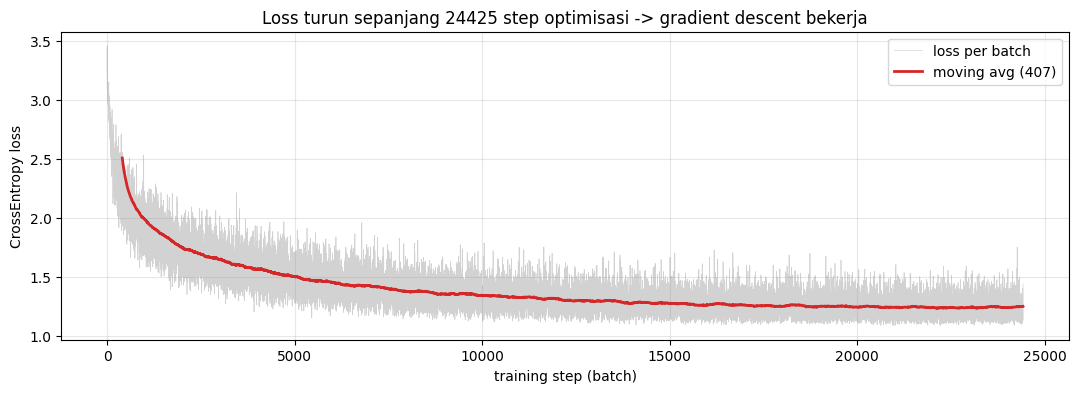

loss step 1 : 3.226  ->  step 24425 : 1.444  (turun 1.782)


In [13]:
plt.figure(figsize=(13, 4))
plt.plot(step_losses, lw=0.5, alpha=0.35, color="gray", label="loss per batch")
k = max(1, len(step_losses) // 60)
if len(step_losses) > k:
    ma = np.convolve(step_losses, np.ones(k) / k, mode="valid")
    plt.plot(range(k - 1, len(step_losses)), ma, lw=2, color="tab:red", label=f"moving avg ({k})")
plt.xlabel("training step (batch)"); plt.ylabel("CrossEntropy loss")
plt.title(f"Loss turun sepanjang {len(step_losses)} step optimisasi -> gradient descent bekerja")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(resolve_path("outputs/v2_exp/train_step_loss.png"), dpi=110); plt.show()
print(f"loss step 1 : {step_losses[0]:.3f}  ->  step {len(step_losses)} : {step_losses[-1]:.3f}"
      f"  (turun {step_losses[0]-step_losses[-1]:.3f})")

### 6b. Learning curve — train vs val (loss, MSE/Brier, macro-F1)

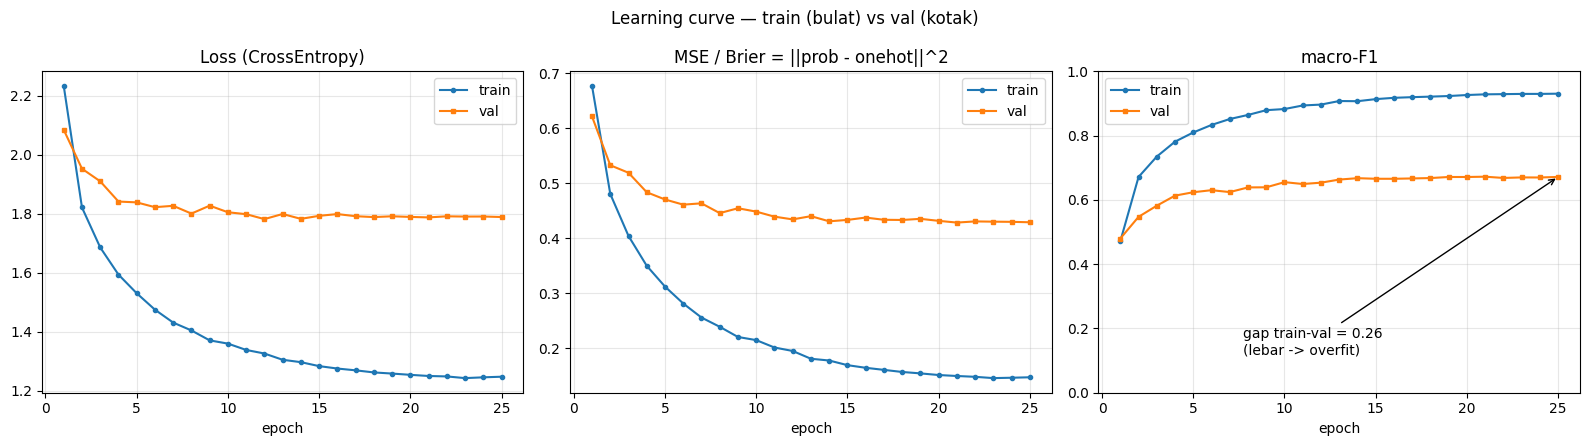

In [14]:
ep = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].plot(ep, history["train_loss"], "o-", ms=3, label="train")
ax[0].plot(ep, history["val_loss"],  "s-", ms=3, label="val")
ax[0].set_title("Loss (CrossEntropy)"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(ep, history["train_mse"], "o-", ms=3, label="train")
ax[1].plot(ep, history["val_mse"],  "s-", ms=3, label="val")
ax[1].set_title("MSE / Brier = ||prob - onehot||^2"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)
ax[2].plot(ep, history["train_macro_f1"], "o-", ms=3, label="train")
ax[2].plot(ep, history["val_macro_f1"],  "s-", ms=3, label="val")
ax[2].set_title("macro-F1"); ax[2].set_xlabel("epoch"); ax[2].set_ylim(0, 1); ax[2].legend(); ax[2].grid(alpha=0.3)
gap = history["train_macro_f1"][-1] - history["val_macro_f1"][-1]
ax[2].annotate(f"gap train-val = {gap:.2f}\n(lebar -> overfit)",
               xy=(list(ep)[-1], history["val_macro_f1"][-1]),
               xytext=(0.3, 0.12), textcoords="axes fraction", arrowprops=dict(arrowstyle="->"))
fig.suptitle("Learning curve — train (bulat) vs val (kotak)", fontsize=12)
plt.tight_layout(); plt.savefig(resolve_path("outputs/v2_exp/train_learning_curve.png"), dpi=110); plt.show()

### 6c. Jadwal learning rate

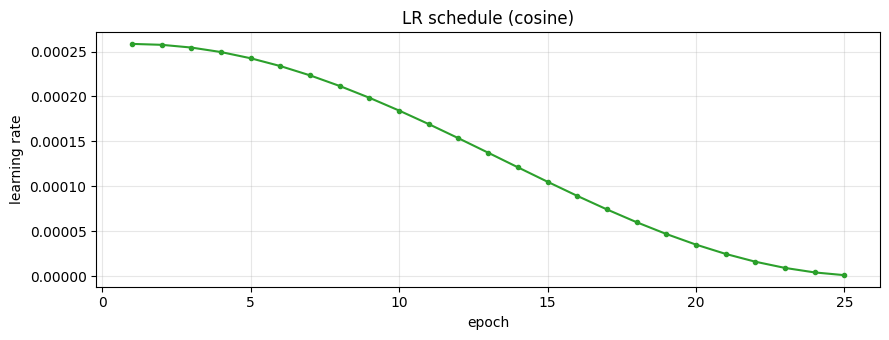

In [15]:
ep = range(1, len(history["lr"]) + 1)
plt.figure(figsize=(9, 3.5))
plt.plot(ep, history["lr"], "o-", ms=3, color="tab:green")
plt.xlabel("epoch"); plt.ylabel("learning rate"); plt.title(f"LR schedule ({cfg['train']['scheduler']})")
plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(resolve_path("outputs/v2_exp/train_lr_schedule.png"), dpi=110); plt.show()

## 7. Evaluasi Test Set (checkpoint terpilih)

In [16]:
best_model = build_model(cfg, num_classes=num_classes).to(device)
ck = load_checkpoint(best_model, ckpt_dir / "best.pth", map_location=str(device))
print(f"best.pth: epoch {ck.get('epoch')} | {ck.get('monitor')} = {ck.get('monitor_value'):.4f}"
      f" | {ck.get('note', 'per-epoch')}")

# perbandingan best vs last di test (FYI)
last_model = build_model(cfg, num_classes=num_classes).to(device)
load_checkpoint(last_model, ckpt_dir / "last.pth", map_location=str(device))
ev = cfg.get("eval", {})
for tag, mdl in [("best", best_model), ("last", last_model)]:
    yt, yp, _ = run_inference(mdl, loaders["test"], device, tta=ev.get("tta", False))
    from sklearn.metrics import f1_score, accuracy_score
    print(f"  {tag:4s}: test acc {accuracy_score(yt, yp):.3f} | macro-F1 {f1_score(yt, yp, average='macro'):.3f}")

best.pth: epoch 21 | val_macro_f1 = 0.6722 | per-epoch
  best: test acc 0.718 | macro-F1 0.674
  last: test acc 0.720 | macro-F1 0.677


In [17]:
y_true, y_pred, y_prob = run_inference(best_model, loaders["test"], device, tta=ev.get("tta", False))
metrics = compute_metrics(y_true, y_pred, y_prob, idx_to_label,
                          subset_min_support=ev.get("subset_min_support", 8))

print(f"TEST (n={metrics['n_test']}, tta={ev.get('tta', False)})")
for k, lab in [("accuracy", "accuracy      "), ("top3_accuracy", "top-3 accuracy"),
               ("macro_f1", "macro-F1      "), ("weighted_f1", "weighted-F1   "),
               ("mse", "MSE / Brier   ")]:
    print(f"  {lab}: {metrics[k]:.3f}")

print("\nkonteks:")
print("  - baseline (1.132 gambar, 12 kelas)   : test macro-F1 ~0.44")
print("  - v1 (5.659 gambar, 11 kelas, tuned)  : test macro-F1 0.78")
print("  - literatur WikiArt style (data penuh): ~0.55-0.65 accuracy")
print(f"  - sekarang (33.9k gambar, {num_classes} kelas, tuning={RUN_TUNING}): test macro-F1 {metrics['macro_f1']:.2f}")
print("  - CATATAN: baseline tebak-acak 22 kelas ~4.5% (vs 11 kelas ~9%) -- macro-F1")
print("    tidak bisa dibandingkan apel-ke-apel antar run beda jumlah kelas.")
print("    Subset shard WikiArt, split TIDAK artist-disjoint. Jangan overclaim.")

metrics["checkpoint"] = {"epoch": ck.get("epoch"), "monitor_value": ck.get("monitor_value"),
                         "note": ck.get("note", "per-epoch")}
metrics["tuning"] = {"ran": RUN_TUNING,
                     "best_params": (study.best_params if RUN_TUNING else TUNED_PARAMS)}
resolve_path(cfg["output"]["metrics_report_path"]).write_text(
    json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8")

TEST (n=5028, tta=True)
  accuracy      : 0.718
  top-3 accuracy: 0.916
  macro-F1      : 0.674
  weighted-F1   : 0.718
  MSE / Brier   : 0.401

konteks:
  - baseline (1.132 gambar, 12 kelas)   : test macro-F1 ~0.44
  - v1 (5.659 gambar, 11 kelas, tuned)  : test macro-F1 0.78
  - literatur WikiArt style (data penuh): ~0.55-0.65 accuracy
  - sekarang (33.9k gambar, 22 kelas, tuning=False): test macro-F1 0.67
  - CATATAN: baseline tebak-acak 22 kelas ~4.5% (vs 11 kelas ~9%) -- macro-F1
    tidak bisa dibandingkan apel-ke-apel antar run beda jumlah kelas.
    Subset shard WikiArt, split TIDAK artist-disjoint. Jangan overclaim.


5051

### 7a. F1 per kelas

                            precision  recall  f1-score  support
Fauvism                         0.250   0.172     0.204     29.0
Expressionism                   0.524   0.549     0.536    317.0
Mannerism_Late_Renaissance      0.553   0.520     0.536     50.0
High_Renaissance                0.577   0.556     0.566     54.0
Minimalism                      0.639   0.575     0.605     40.0
Pop_Art                         0.778   0.500     0.609     28.0
Post_Impressionism              0.604   0.631     0.617    461.0
Abstract_Expressionism          0.670   0.615     0.641    109.0
Pointillism                     0.576   0.731     0.644     26.0
Realism                         0.697   0.673     0.685    830.0
Rococo                          0.706   0.667     0.686     72.0
Art_Nouveau                     0.680   0.723     0.701    274.0
Color_Field_Painting            0.671   0.736     0.702     72.0
Romanticism                     0.697   0.714     0.705    409.0
Cubism                   

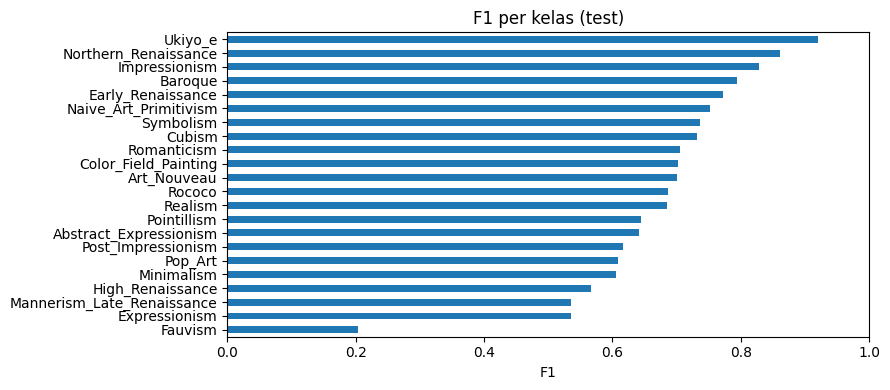

In [18]:
rep = metrics["per_class"]
df = (pd.DataFrame({k: rep[k] for k in class_names}).T
        [["precision", "recall", "f1-score", "support"]].round(3).sort_values("f1-score"))
print(df)
ax = df["f1-score"].plot(kind="barh", figsize=(9, 4), color="tab:blue")
ax.set_xlim(0, 1); ax.set_xlabel("F1"); ax.set_title("F1 per kelas (test)")
plt.tight_layout(); plt.show()

### 7b. Confusion matrix (ternormalisasi per baris)

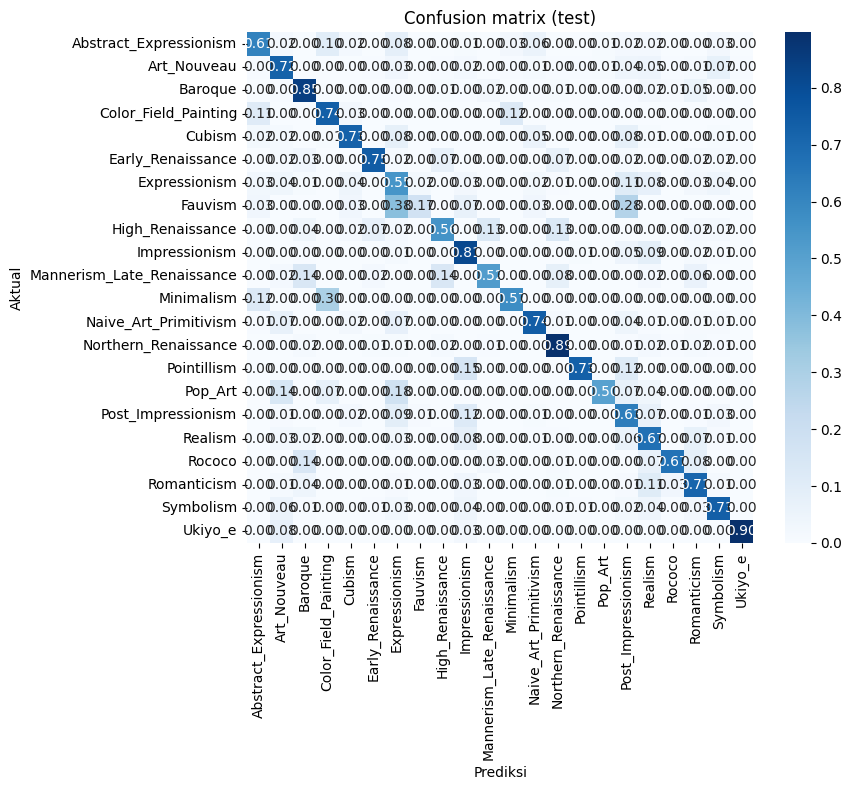

In [19]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(9, 8))
try:
    import seaborn as sns
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=ax, cbar=True)
except ImportError:
    im = ax.imshow(cm_norm, cmap="Blues")
    ax.set_xticks(range(num_classes), class_names, rotation=90)
    ax.set_yticks(range(num_classes), class_names); fig.colorbar(im, ax=ax)
ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual"); ax.set_title("Confusion matrix (test)")
plt.tight_layout(); plt.savefig(resolve_path(cfg["output"]["confusion_matrix_path"]), dpi=110); plt.show()

### 7c. Contoh prediksi acak (hijau = benar, merah = salah)

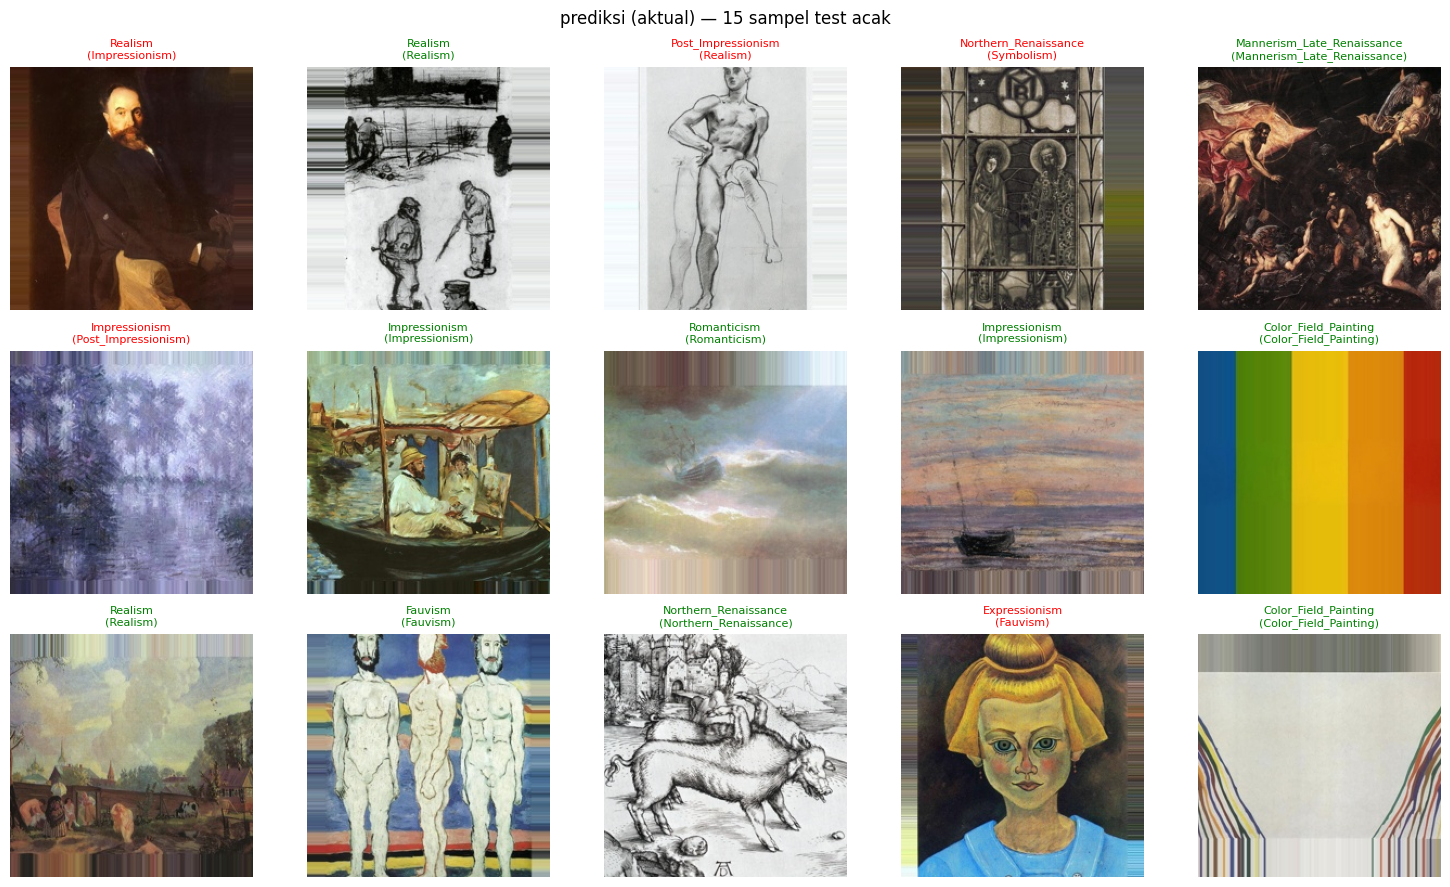

In [20]:
# ambil 15 indeks ACAK dari test set (bukan batch pertama yg bias shard-0)
test_ds = loaders["test"].dataset
rng = np.random.default_rng(cfg["seed"])
pick = rng.choice(len(test_ds), size=15, replace=False)
xs = torch.stack([test_ds[i][0] for i in pick])
ys = [test_ds[i][1] for i in pick]
with torch.no_grad():
    pr = torch.softmax(best_model(xs.to(device)), dim=1).argmax(1).cpu().tolist()

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for ax, xi, t, p in zip(axes.flat, xs, ys, pr):
    ax.imshow(denorm(xi)); ax.axis("off")
    ax.set_title(f"{idx_to_label[p]}\n({idx_to_label[t]})", fontsize=8,
                 color="green" if t == p else "red")
fig.suptitle("prediksi (aktual) — 15 sampel test acak"); plt.tight_layout(); plt.show()